# 01 — Tổng quan dữ liệu GeoLife

Thống kê cấu trúc/quy mô toàn dataset và audit nhóm users 000, 001, 002.
Giữ nguyên records; chưa cleaning, stay detection, clustering hoặc inference.
Ảnh/cache ở `artifacts/overview/`. Các phần dưới gồm code, bảng/chart và giải thích cần thiết.

## 1. Môi trường và dataset

Kernel là tiến trình Python thực thi cell. Chọn `.venv` / **Python (GeoLife)** của dự án.
Dataset đã được giải nén tại `data/Geolife Trajectories 1.3/`.
Notebook tự tìm đường dẫn tương đối từ thư mục dự án; mở trực tiếp trong VS Code rồi chạy cell,
không cần thiết lập biến môi trường. `GEOLIFE_DATASET` chỉ là tùy chọn cho một thư mục khác.

In [1]:
from pathlib import Path, PurePosixPath
import hashlib
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'geolife_inference').is_dir())
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Hãy chọn kernel Python (GeoLife).'
# Đường dẫn tương đối: đi cùng project, không phụ thuộc biến môi trường.
DATASET = ROOT / 'data' / 'Geolife Trajectories 1.3'
custom_dataset = os.environ.get('GEOLIFE_DATASET')
if custom_dataset and Path(custom_dataset).expanduser().is_dir():
    DATASET = Path(custom_dataset).expanduser().resolve()
assert DATASET.is_dir(), f'Chưa có dataset đã giải nén tại: {DATASET}'
OUT = ROOT / 'artifacts' / 'overview'
OUT.mkdir(parents=True, exist_ok=True)
USERS = ['000', '001', '002']

get_ipython().run_line_magic('matplotlib', 'inline')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def show_chart(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

display(pd.Series({'Python': sys.version.split()[0], 'pandas': pd.__version__,
                   'NumPy': np.__version__, 'Timestamp parsing': 'UTC',
                   'Dataset folder': str(DATASET)}, name='Môi trường'))

Python                                                          3.11.4
pandas                                                           2.2.3
NumPy                                                            2.4.4
Timestamp parsing                                                  UTC
Dataset folder       E:\QUY\Geolife-Trajectories\data\Geolife Traje...
Name: Môi trường, dtype: object

## 2. Cấu trúc dataset

Phân biệt ba đơn vị:

- **GPS point:** một phép ghi tọa độ tại một timestamp.
- **Trajectory:** một file ghi lại một chuỗi GPS points; không mặc định là một lần đi làm hay một lần ghé.
- **User:** nhiều trajectories có thể thuộc cùng một người, với độ dài lịch sử rất khác nhau.

Ta liệt kê file trong thư mục đã giải nén. Chưa load toàn bộ GPS vào RAM.

In [2]:
members = sorted(path for path in DATASET.rglob('*') if path.is_file())
trajectory_paths = [path for path in members if path.suffix.lower() == '.plt']
trajectory_names = [path.relative_to(DATASET).as_posix() for path in trajectory_paths]
label_names = [path.relative_to(DATASET).as_posix() for path in members if path.name == 'labels.txt']
uncompressed_bytes = sum(path.stat().st_size for path in members)

by_user = {}
for name in trajectory_names:
    path = PurePosixPath(name)
    assert path.parent.name == 'Trajectory', 'Cấu trúc thư mục khác kỳ vọng; cần xem lại trước khi tiếp tục.'
    by_user.setdefault(path.parent.parent.name, []).append(name)

display(pd.Series({'Users': len(by_user), 'PLT files / trajectories': len(trajectory_names),
                   'Transportation label files': len(label_names),
                   'Dataset GiB': round(uncompressed_bytes / 2**30, 3)}, name='Inventory toàn dataset'))
display(pd.DataFrame({'Ví dụ đường dẫn tương đối': trajectory_names[:4]}))

Users                           182.000
PLT files / trajectories      18670.000
Transportation label files       69.000
Dataset GiB                       1.554
Name: Inventory toàn dataset, dtype: float64

,Ví dụ đường dẫn tương đối
0,Data/000/Trajectory/20081023025304.plt
1,Data/000/Trajectory/20081024020959.plt
2,Data/000/Trajectory/20081026134407.plt
3,Data/000/Trajectory/20081027115449.plt


### Định dạng file `.plt`

Theo [GeoLife User Guide](https://www.microsoft.com/en-us/research/publication/geolife-gps-trajectory-dataset-user-guide/),
section 4.1 trong PDF đi kèm ZIP: bỏ sáu header khi parse; latitude/longitude là degrees,
altitude là **feet**, `-777` là altitude không hợp lệ. Date/time là **GMT (UTC)**.

| Trường | Nội dung | Chú ý |
|---|---|---|
| 1, 2 | latitude, longitude | Không coi degrees là meters |
| 3 | trường dự phòng | Dataset đặt 0 |
| 4 | altitude feet | `-777` không phải độ cao thật |
| 5 | serial day từ 1899-12-30 | Một biểu diễn khác của thời gian |
| 6, 7 | date, time | Notebook chọn làm nguồn timestamp UTC |

`labels.txt` ghi phương tiện di chuyển, không phải nhãn nhà/nơi làm việc.

In [3]:
sample_name = trajectory_names[0]
with (DATASET / sample_name).open(encoding='utf-8-sig') as stream:
    sample_lines = [stream.readline().rstrip() for _ in range(11)]
display(Markdown('**File mẫu:** `' + sample_name + '`'))
display(pd.DataFrame({'Dòng': range(1, 12), 'Nội dung gốc': sample_lines}))

**File mẫu:** `Data/000/Trajectory/20081023025304.plt`

,Dòng,Nội dung gốc
0,1,Geolife trajectory
1,2,WGS 84
2,3,Altitude is in Feet
3,4,Reserved 3
4,5,"0,2,255,My Track,0,0,2,8421376"
5,6,0
6,7,"39.984702,116.318417,0,492,39744.1201851852,20..."
7,8,"39.984683,116.31845,0,492,39744.1202546296,200..."
8,9,"39.984686,116.318417,0,492,39744.1203125,2008-..."
9,10,"39.984688,116.318385,0,492,39744.1203703704,20..."


Số GPS points không phải số lần ghé. Khoảng không có GPS records không chứng minh người dùng đứng yên.

## 3. Phân phối dung lượng dữ liệu giữa các users

Đếm trajectories là liệt kê file; đếm points cần đọc dòng dữ liệu.
Cell dưới đọc lần lượt các PLT, đếm **nonblank record lines sau sáu header**.
Đây chưa phải số points hợp lệ sau validation. Lần đầu đọc khoảng 1,55 GiB dữ liệu từ ổ đĩa.
Các lần sau dùng cache nếu danh sách file, kích thước và thời gian sửa không đổi.
Đây là metadata fingerprint, không phải kiểm tra checksum nội dung từng file.
Đặt `RECOUNT=True` để tự đếm lại khi cần.

In [4]:
file_metadata = [(name, (DATASET / name).stat().st_size, (DATASET / name).stat().st_mtime_ns)
                 for name in trajectory_names]
dataset_fingerprint = hashlib.sha256(json.dumps(file_metadata).encode('utf-8')).hexdigest()
RECOUNT = False
cache_path = OUT / 'record-counts.json'
cached = json.loads(cache_path.read_text(encoding='utf-8')) if cache_path.exists() else {}
if not RECOUNT and cached.get('dataset_fingerprint') == dataset_fingerprint:
    counts = cached['counts']
    print('Dùng record-count cache đã khớp file names, sizes và modified times.')
else:
    counts = {}
    for user, names in sorted(by_user.items()):
        count = 0
        for name in names:
            with (DATASET / name).open('rb') as stream:
                for _ in range(6):
                    stream.readline()
                count += sum(bool(line.strip()) for line in stream)
        counts[user] = count
    cache_path.write_text(json.dumps({'dataset_fingerprint': dataset_fingerprint,
                                     'counts': counts}), encoding='utf-8')
    print('Đã đếm trực tiếp record lines của toàn dataset đã giải nén.')

inventory = pd.DataFrame([{'user_id': u, 'trajectories': len(names), 'record_lines': counts[u]}
                          for u, names in sorted(by_user.items())])
assert len(inventory) == len(by_user)
print(f"Tổng record lines: {inventory.record_lines.sum():,}; users: {len(inventory)}.")
display(inventory[['trajectories', 'record_lines']].describe(percentiles=[.25, .5, .75, .95]).round(1))

Dùng record-count cache đã khớp file names, sizes và modified times.
Tổng record lines: 24,876,978; users: 182.


,trajectories,record_lines
count,182.0,182.0
mean,102.6,136686.7
std,250.1,265635.4
min,1.0,17.0
25%,8.0,3359.0
50%,27.5,35181.5
75%,89.8,143041.5
95%,394.8,615244.1
max,2153.0,2156994.0


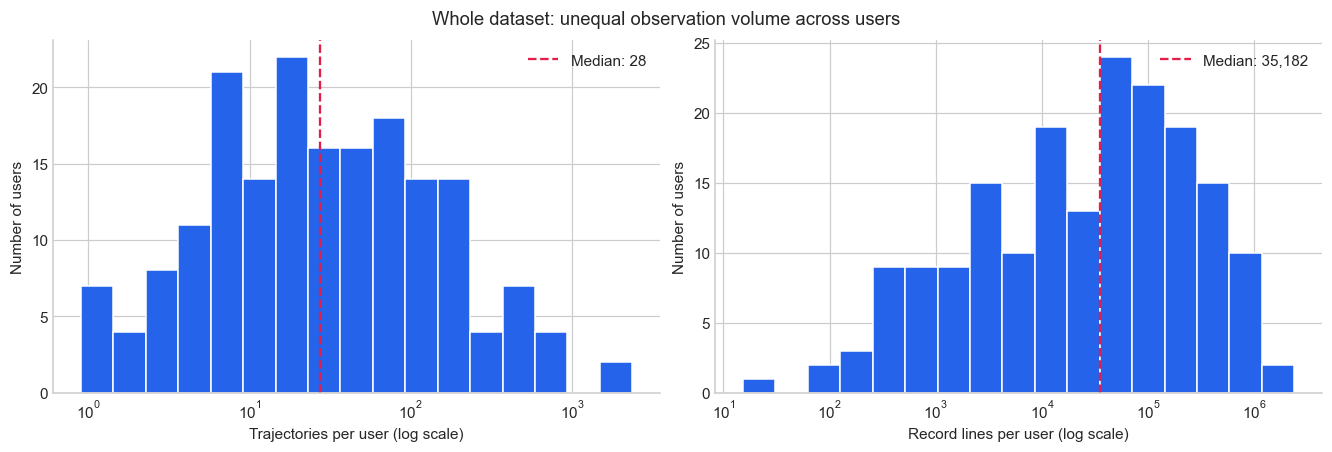

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, column, label in zip(axes, ['trajectories', 'record_lines'], ['Trajectories per user', 'Record lines per user']):
    values = inventory[column]
    bins = np.geomspace(max(1, values.min()) * .9, values.max() * 1.1, 18)
    ax.hist(values, bins=bins, color='#2563eb', edgecolor='white')
    ax.set_xscale('log')
    ax.set_xlabel(label + ' (log scale)')
    ax.set_ylabel('Number of users')
    ax.axvline(values.median(), color='#e11d48', linestyle='--', label=f'Median: {values.median():,.0f}')
    ax.legend()
fig.suptitle('Whole dataset: unequal observation volume across users')
show_chart(fig, '01_user_volume')

In [6]:
top10_share = inventory.nlargest(10, 'record_lines').record_lines.sum() / inventory.record_lines.sum()
display(Markdown(f"**Nhận xét từ dữ liệu:** trajectories/user từ **{inventory.trajectories.min():,}** "
                 f"đến **{inventory.trajectories.max():,}**, median **{inventory.trajectories.median():,.0f}**. "
                 f"10 users nhiều record lines nhất chiếm **{top10_share:.1%}** tổng record lines. "
                 "Không nên gộp mọi point rồi nghĩ mỗi người đóng góp ngang nhau."))

**Nhận xét từ dữ liệu:** trajectories/user từ **1** đến **2,153**, median **28**. 10 users nhiều record lines nhất chiếm **40.8%** tổng record lines. Không nên gộp mọi point rồi nghĩ mỗi người đóng góp ngang nhau.

**Cách đọc chart:** trục X dùng log vì user ít/nhiều dữ liệu chênh lệch lớn; trục Y vẫn là số users.
Cột cao không có nghĩa người đó đi xa hoặc ghé nhiều nơi; chỉ có nhiều users nằm trong khoảng dung lượng đó.

## 4. Quality audit trên ba users

Chọn `000`, `001`, `002` để nối với bản thử trước và giữ thời gian/RAM vừa phải.
Đây là **development subset**, không phải mẫu đại diện ngẫu nhiên. Bảng dưới đặt họ vào phân phối toàn bộ.
Mọi thống kê/chart từ phần này trở đi chỉ thuộc subset, trừ khi ghi rõ khác.

In [7]:
assert set(USERS) <= set(by_user)
selection = inventory[inventory.user_id.isin(USERS)].copy()
selection['trajectory_percentile_in_dataset'] = selection.trajectories.map(
    lambda value: 100 * inventory.trajectories.le(value).mean())
display(selection)

RAW_COLUMNS = ['latitude', 'longitude', 'reserved', 'altitude_ft', 'serial_day', 'date', 'time']
parts = []
for user in USERS:
    for name in by_user[user]:
        with (DATASET / name).open(encoding='utf-8-sig') as text:
            frame = pd.read_csv(text, skiprows=6, header=None, dtype='string', keep_default_na=False)
        assert frame.shape[1] == 7, f'Sai số cột: {name}'
        frame.columns = RAW_COLUMNS
        frame['user_id'] = user
        frame['trajectory_id'] = PurePosixPath(name).stem
        frame['source_row'] = np.arange(7, len(frame) + 7)
        parts.append(frame)
raw = pd.concat(parts, ignore_index=True)
del parts
assert len(raw) == selection.record_lines.sum()
display(raw.head(5))
print(f'Subset: {len(raw):,} record rows. Chưa bỏ duplicates, outliers hay invalid rows.')

,user_id,trajectories,record_lines,trajectory_percentile_in_dataset
0,000,171,173870,86.813187
1,001,71,108607,69.780220
2,002,175,248217,87.362637


,latitude,longitude,reserved,altitude_ft,serial_day,date,time,user_id,trajectory_id,source_row
0,39.984702,116.318417,0,492,39744.1201851852,2008-10-23,02:53:04,000,20081023025304,7
1,39.984683,116.31845,0,492,39744.1202546296,2008-10-23,02:53:10,000,20081023025304,8
2,39.984686,116.318417,0,492,39744.1203125,2008-10-23,02:53:15,000,20081023025304,9
3,39.984688,116.318385,0,492,39744.1203703704,2008-10-23,02:53:20,000,20081023025304,10
4,39.984655,116.318263,0,492,39744.1204282407,2008-10-23,02:53:25,000,20081023025304,11


Subset: 530,694 record rows. Chưa bỏ duplicates, outliers hay invalid rows.


### Parsing và cleaning

`raw` giữ token strings đúng như đã đọc. Ta tạo **bản sao `parsed`**, chuyển số/time và thêm cờ lỗi;
giá trị không parse được thành NaN/NaT để đếm, **không xóa dòng**. `-777` vẫn giữ trong altitude feet;
cột meters mới đánh dấu missing đúng định nghĩa nguồn.

Quy tắc audit: tọa độ phải finite và đúng bounds; duplicate point key là
user/trajectory/timestamp/lat/lon (chưa dùng altitude); timestamp conflict là cùng user/trajectory/time
nhưng có hơn một tọa độ hợp lệ. Các cờ có thể cùng đúng trên một dòng, không cộng để suy số dòng cần xóa.

In [8]:
parsed = raw.copy()
for column in ['latitude', 'longitude', 'altitude_ft', 'serial_day']:
    parsed[column] = pd.to_numeric(raw[column], errors='coerce').astype('float64')
parsed['timestamp'] = pd.to_datetime(raw.date + ' ' + raw.time,
    format='%Y-%m-%d %H:%M:%S', errors='coerce', utc=True)
parsed['altitude_m'] = parsed.altitude_ft.mask(parsed.altitude_ft.eq(-777)) * .3048

coordinate_ok = (np.isfinite(parsed.latitude) & parsed.latitude.between(-90, 90)
                 & np.isfinite(parsed.longitude) & parsed.longitude.between(-180, 180))
time_ok = parsed.timestamp.notna()
parsed['bad_coordinate'] = ~coordinate_ok
parsed['bad_timestamp'] = ~time_ok
parsed['missing_altitude'] = ~np.isfinite(parsed.altitude_ft) | parsed.altitude_ft.eq(-777)
parsed['any_empty_raw_field'] = raw[RAW_COLUMNS].isna().any(axis=1) | raw[RAW_COLUMNS].eq('').any(axis=1)
valid = coordinate_ok & time_ok
point_keys = ['user_id', 'trajectory_id', 'timestamp', 'latitude', 'longitude']
parsed['duplicate_point_extra'] = False
parsed.loc[valid, 'duplicate_point_extra'] = parsed.loc[valid].duplicated(point_keys)
distinct_positions = parsed.loc[valid, point_keys].drop_duplicates()
conflict_keys = ['user_id', 'trajectory_id', 'timestamp']
conflicting_positions = distinct_positions[distinct_positions.duplicated(conflict_keys, keep=False)]
conflict_groups = conflicting_positions.groupby('user_id').size()

quality_columns = ['bad_coordinate', 'bad_timestamp', 'missing_altitude',
                   'any_empty_raw_field', 'duplicate_point_extra']
quality = parsed.groupby('user_id')[quality_columns].sum().astype(int)
quality['distinct_positions_in_timestamp_conflicts'] = conflict_groups.reindex(quality.index, fill_value=0)
quality['rows_retained'] = parsed.groupby('user_id').size()
assert len(parsed) == len(raw), 'Audit phải giữ nguyên số dòng.'
display(quality)

,bad_coordinate,bad_timestamp,missing_altitude,any_empty_raw_field,duplicate_point_extra,distinct_positions_in_timestamp_conflicts,rows_retained
user_id,,,,,,,
000,0,0,0,0,0,0,173870
001,0,0,0,0,0,0,108607
002,0,0,1,0,0,6,248217


In [9]:
# Xem trường hợp cụ thể thay vì chỉ tin tổng số lỗi.
flagged = parsed[quality_columns[:-1]].any(axis=1) | parsed.index.isin(conflicting_positions.index)
display(parsed.loc[flagged, ['user_id', 'trajectory_id', 'source_row', 'latitude', 'longitude',
                             'timestamp', 'altitude_ft', 'missing_altitude']].head(12))

# Raw-order audit riêng: không sắp xếp trước khi kiểm tra thứ tự timestamp của file gốc.
source_dt = parsed.groupby(['user_id', 'trajectory_id'], sort=False).timestamp.diff().dt.total_seconds()
display(pd.DataFrame({'zero_timestamp_deltas': source_dt.eq(0).groupby(parsed.user_id).sum(),
                      'negative_timestamp_deltas': source_dt.lt(0).groupby(parsed.user_id).sum()}))

,user_id,trajectory_id,source_row,latitude,longitude,timestamp,altitude_ft,missing_altitude
311761,002,20081101010123,439,39.895867,116.272799,2008-11-01 01:09:31+00:00,95.0,False
311762,002,20081101010123,440,39.895870,116.272962,2008-11-01 01:09:31+00:00,96.0,False
426027,002,20090125011404,525,37.416330,110.771849,2009-01-25 05:26:27+00:00,2534.0,False
426028,002,20090125011404,526,37.416802,110.772034,2009-01-25 05:26:27+00:00,1960.0,False
484843,002,20090216200646,600,39.897409,116.383810,2009-02-17 00:20:57+00:00,-777.0,True
518709,002,20090312132809,253,39.902621,116.368067,2009-03-12 13:43:40+00:00,321.0,False
518710,002,20090312132809,254,39.902545,116.368070,2009-03-12 13:43:40+00:00,321.0,False


,zero_timestamp_deltas,negative_timestamp_deltas
user_id,,
000,0,0
001,0,0
002,3,0


**Đọc bảng:** zero invalid coordinates chỉ nghĩa là không gặp lỗi bounds trong subset;
GPS vẫn có thể bị jitter/jump. Missing altitude không tự làm lat/lon/time vô dụng.
Conflict count là số distinct positions trong nhóm conflict, chưa phải số points cần xóa.
Notebook 02 xử lý và đối chiếu từng cleaning rule.

## 5. Sampling và gaps

Tạo bản sao `timeline` sắp xếp stable theo user/trajectory/time để tính **consecutive pairs trong cùng file**.
Không nối cuối file này sang đầu file khác. Tất cả rows vẫn còn; timestamp lỗi không tham gia phép trừ hợp lệ.
`dt=0`, `dt<0`, undefined được báo riêng. Chỉ positive intervals đi vào sampling chart.

Ngưỡng 5 phút dưới đây chỉ là **mốc tham chiếu của bản thử**, chưa được chốt làm cleaning/stay rule.

In [10]:
timeline = parsed.sort_values(['user_id', 'trajectory_id', 'timestamp', 'source_row'],
                             kind='stable', na_position='last').copy()
previous = timeline.groupby(['user_id', 'trajectory_id'], sort=False).shift(1)
timeline['dt_seconds'] = (timeline.timestamp - previous.timestamp).dt.total_seconds()
positive_dt = timeline.loc[timeline.dt_seconds > 0, ['user_id', 'dt_seconds']]
sampling = positive_dt.groupby('user_id').dt_seconds.quantile([.5, .95, .99, 1]).unstack()
sampling.columns = ['median_s', 'p95_s', 'p99_s', 'max_s']
sampling['positive_pair_count'] = positive_dt.groupby('user_id').size()
sampling['pairs_over_5min'] = positive_dt.dt_seconds.gt(300).groupby(positive_dt.user_id).sum()
sampling['over_5min_fraction'] = sampling.pairs_over_5min / sampling.positive_pair_count
display(sampling)
assert len(timeline) == len(raw)

,median_s,p95_s,p99_s,max_s,positive_pair_count,pairs_over_5min,over_5min_fraction
user_id,,,,,,,
000,5.0,5.0,10.0,20990.0,173699,653,0.003759
001,4.0,5.0,5.0,39525.0,108536,206,0.001898
002,5.0,5.0,5.0,21590.0,248039,566,0.002282


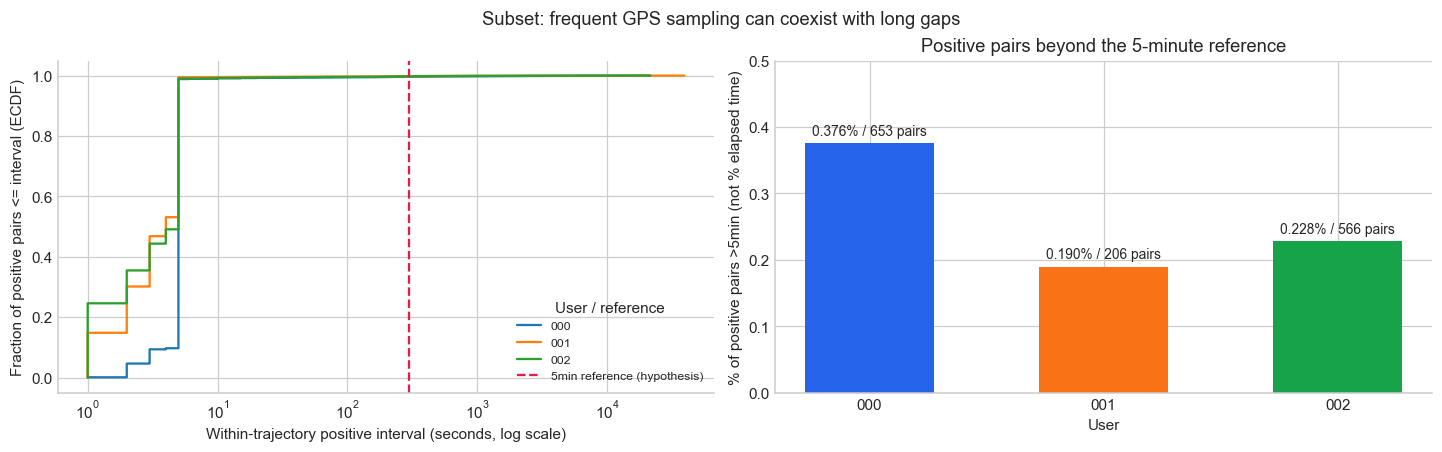

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for user in USERS:
    values = positive_dt.loc[positive_dt.user_id == user, 'dt_seconds'].sort_values().to_numpy()
    axes[0].step(values, np.arange(1, len(values) + 1) / len(values), where='post', label=user)
axes[0].set_xscale('log')
axes[0].set_xlabel('Within-trajectory positive interval (seconds, log scale)')
axes[0].set_ylabel('Fraction of positive pairs <= interval (ECDF)')
axes[0].axvline(300, color='#e11d48', linestyle='--', label='5min reference (hypothesis)')
axes[0].legend(title='User / reference', fontsize=8)

gap_percent = sampling.reindex(USERS).over_5min_fraction * 100
bars = axes[1].bar(USERS, gap_percent, color=['#2563eb', '#f97316', '#16a34a'], width=.55)
for bar, user in zip(bars, USERS):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + .012,
                 f'{gap_percent.loc[user]:.3f}% / {sampling.loc[user, "pairs_over_5min"]:,.0f} pairs',
                 ha='center', fontsize=9)
axes[1].set_ylim(0, max(.5, gap_percent.max() * 1.3))
axes[1].set_title('Positive pairs beyond the 5-minute reference')
axes[1].set_xlabel('User')
axes[1].set_ylabel('% of positive pairs >5min (not % elapsed time)')
axes[1].tick_params(axis='x', rotation=0)
fig.suptitle('Subset: frequent GPS sampling can coexist with long gaps')
show_chart(fig, '02_sampling')

**ECDF:** Tại X=5 giây, Y cho biết phần trăm positive pairs có interval không quá 5 giây.
Đường lên nhanh ở 5 giây nghĩa sampling thường quanh mức đó; phần đuôi phải cho biết gaps dài.
Chart bên phải tính theo **số pairs**, không theo tổng thời gian — rất ít gaps dài vẫn có thể chiếm nhiều giờ.

In [12]:
gap_reference = 300  # Chỉ thử đọc diagnostics, chưa áp dụng rule.
time_budget = positive_dt.assign(long_gap=lambda d: d.dt_seconds > gap_reference).groupby('user_id').agg(
    positive_interval_seconds=('dt_seconds', 'sum'),
    within_file_span_pairs=('dt_seconds', 'size'))
long_seconds = positive_dt.loc[positive_dt.dt_seconds > gap_reference].groupby('user_id').dt_seconds.sum()
time_budget['seconds_in_gaps_over_5min'] = long_seconds.reindex(time_budget.index, fill_value=0)
time_budget['gap_time_share_of_within_file_positive_intervals'] = (
    time_budget.seconds_in_gaps_over_5min / time_budget.positive_interval_seconds)
display(time_budget)
display(timeline.nlargest(6, 'dt_seconds')[['user_id', 'trajectory_id', 'source_row', 'timestamp', 'dt_seconds']])

,positive_interval_seconds,within_file_span_pairs,seconds_in_gaps_over_5min,gap_time_share_of_within_file_positive_intervals
user_id,,,,
000,3339809.0,173699,2431902.0,0.728156
001,1134330.0,108536,717434.0,0.632474
002,2522978.0,248039,1536610.0,0.609046


,user_id,trajectory_id,source_row,timestamp,dt_seconds
189559,001,20081026081229,1856,2008-10-26 22:21:56+00:00,39525.0
245925,001,20081119104736,1784,2008-11-19 22:12:13+00:00,28245.0
345126,002,20081112001312,680,2008-11-12 11:36:37+00:00,21590.0
256983,001,20081207030135,824,2008-12-07 09:52:05+00:00,21258.0
378128,002,20081201235901,710,2008-12-02 10:17:34+00:00,21070.0
339075,002,20081109233203,816,2008-11-10 10:00:54+00:00,21024.0


Hai tọa độ giống nhau cách nhau hai giờ chỉ mô tả hai đầu khoảng ghi nhận,
không chứng minh user ở lại đó suốt hai giờ. Mẫu số time budget ở trên là sum positive intervals
trong từng file; không phải calendar coverage hoặc dwell time.

## 6. Tổng hợp kết quả

Các con số dưới đây được tính trực tiếp từ lần chạy, phạm vi toàn dataset và subset được ghi riêng.

In [13]:
summary = {
    'dataset_fingerprint': dataset_fingerprint,
    'whole_dataset_users': len(inventory),
    'whole_dataset_trajectories': len(trajectory_names),
    'whole_dataset_record_lines': int(inventory.record_lines.sum()),
    'selected_users': USERS,
    'subset_raw_rows': len(raw),
    'subset_parsed_rows': len(parsed),
    'rows_removed': 0,
    'quality': quality.reset_index().to_dict('records'),
    'sampling': sampling.reset_index().to_dict('records'),
    'phase_status': 'overview_completed',
}
assert len(raw) == len(parsed) == len(timeline), 'Audit phải giữ nguyên số dòng.'
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
sentences = [f"- Toàn dataset: **{len(inventory)} users**, **{len(trajectory_names):,} trajectories**, "
             f"**{inventory.record_lines.sum():,} record lines**; chưa validate mọi giá trị của toàn dataset.",
             f"- Subset {', '.join(USERS)}: **{len(raw):,} rows trước và sau audit; 0 rows bị xóa**."]
for user in USERS:
    s = sampling.loc[user]
    sentences.append(f"- User {user}: median interval **{s.median_s:.0f}s**, p99 **{s.p99_s:.0f}s**, "
                     f"**{s.pairs_over_5min:.0f} pairs >5min**. Đây là số pairs, không phải tổng thời gian.")
display(Markdown(chr(10).join(sentences)))

- Toàn dataset: **182 users**, **18,670 trajectories**, **24,876,978 record lines**; chưa validate mọi giá trị của toàn dataset.
- Subset 000, 001, 002: **530,694 rows trước và sau audit; 0 rows bị xóa**.
- User 000: median interval **5s**, p99 **10s**, **653 pairs >5min**. Đây là số pairs, không phải tổng thời gian.
- User 001: median interval **4s**, p99 **5s**, **206 pairs >5min**. Đây là số pairs, không phải tổng thời gian.
- User 002: median interval **5s**, p99 **5s**, **566 pairs >5min**. Đây là số pairs, không phải tổng thời gian.

### Kết luận

- Giữ raw records nguyên vẹn; notebook 02 thực hiện cleaning trên bản sao và so trước–sau.
- GPS point counts không phải visit counts hoặc dwell time.
- Long GPS gaps không được lấp thành stationary time.
- Các quyết định xử lý timestamp conflict cần ghi rõ giả định và giới hạn.

Nguồn định dạng: User Guide 1.3 đi kèm dataset và [Microsoft](https://www.microsoft.com/en-us/research/publication/geolife-gps-trajectory-dataset-user-guide/).